<a href="https://colab.research.google.com/github/nizarbanu/TF-IDF_Autoencoders/blob/main/TFIDF_Text_Autoencoder_Learner_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text Autoencoder: Learning Latent Representations using TF-IDF

## Learning objectives

By completing this notebook, you will be able to:

1. Convert text documents into numerical feature vectors using TF-IDF.
2. Understand why text vectors can be high-dimensional and sparse.
3. Build an encoder–bottleneck–decoder architecture.
4. Train an autoencoder to reconstruct TF-IDF feature vectors.
5. Extract compact latent representations from the encoder.
6. Visualise latent representations in two dimensions.
7. Examine how the latent dimension affects reconstruction quality.
8. Work through a small numerical TF-IDF example and calculate reconstruction loss.
9. Interpret the learned latent representation and identify the limitations of reconstruction-based learning.

> **Important:** This notebook uses a TF-IDF-based dense autoencoder. It reconstructs numerical TF-IDF vectors, not the original sentences word by word. TF-IDF does not preserve word order. This is different from an RNN, which processes a sequence of tokens over time.


## 1. Understanding the task

An autoencoder learns to reproduce its input. It contains three main parts:

- **Encoder:** maps the input vector to a compact representation.
- **Latent space:** stores the compressed representation.
- **Decoder:** attempts to reconstruct the original input vector.

For text, we first represent each document numerically. In this practical, TF-IDF converts a collection of documents into a document–term matrix.

$$
X \in \mathbb{R}^{N \times V}
$$

Here, \(N\) is the number of documents and \(V\) is the vocabulary size. The autoencoder learns a mapping from the original \(V\)-dimensional vector to a smaller latent vector of dimension \(d\), and then reconstructs the \(V\)-dimensional input.

$$
X \rightarrow \text{Encoder} \rightarrow Z \rightarrow \text{Decoder} \rightarrow \hat{X}
$$

The training objective is to minimise reconstruction error between \(X\) and $\hat{X}$.


## 2. Import the required libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 3. Prepare a small text dataset

We will use a small illustrative dataset with four broad themes: **technology, education, healthcare and sports**.

Each document is a short text sample. The category labels are retained only to help us colour the latent-space visualisation. They are **not** provided to the autoencoder during training. This is an unsupervised learning task.


In [ ]:
documents = [
    # Technology
    "Artificial intelligence and machine learning are changing modern technology.",
    "Deep learning models can recognise objects in digital images.",
    "Cloud computing provides scalable storage and computing services.",
    "Cybersecurity protects computer networks from malicious attacks.",
    "Data science uses statistics and algorithms to discover useful patterns.",
    "Robotics combines sensors software and intelligent control systems.",
    "Natural language processing helps computers understand human language.",
    "Neural networks learn complex patterns from large datasets.",

    # Education
    "Teachers use digital tools to support classroom learning.",
    "Online learning platforms provide access to educational resources.",
    "Students develop programming skills through practical exercises.",
    "Personalised learning adapts educational content to student needs.",
    "Universities offer courses in science technology and engineering.",
    "Educational assessment measures student understanding and progress.",
    "Virtual classrooms support learning from different locations.",
    "Teachers prepare lessons activities and learning materials.",

    # Healthcare
    "Doctors use medical images to support disease diagnosis.",
    "Healthcare data can help predict patient health risks.",
    "Hospitals use digital systems to manage patient records.",
    "Medical research develops treatments for different diseases.",
    "Wearable devices monitor heart rate and physical activity.",
    "Artificial intelligence can assist clinical decision making.",
    "Patient safety is important in healthcare services.",
    "Public health programmes promote disease prevention.",

    # Sports
    "Football players practise passing shooting and teamwork.",
    "Cricket teams analyse match statistics and player performance.",
    "Athletes follow training plans to improve physical fitness.",
    "Sports coaches study strategies before important competitions.",
    "Basketball players develop speed coordination and shooting skills.",
    "Fitness tracking devices measure steps and exercise activity.",
    "The team won the tournament after a close final match.",
    "Regular exercise improves strength endurance and health."
]

labels = (
    ["Technology"] * 8 +
    ["Education"] * 8 +
    ["Healthcare"] * 8 +
    ["Sports"] * 8
)

data = pd.DataFrame({"text": documents, "category": labels})
data.head(10)

,text,category
0,Artificial intelligence and machine learning a...,Technology
1,Deep learning models can recognise objects in ...,Technology
2,Cloud computing provides scalable storage and ...,Technology
3,Cybersecurity protects computer networks from ...,Technology
4,Data science uses statistics and algorithms to...,Technology
5,Robotics combines sensors software and intelli...,Technology
6,Natural language processing helps computers un...,Technology
7,Neural networks learn complex patterns from la...,Technology
8,Teachers use digital tools to support classroo...,Education
9,Online learning platforms provide access to ed...,Education


### Observe the dataset

In [ ]:
print("Number of documents:", len(data))
print("\nCategory distribution:")
print(data["category"].value_counts())

for category in data["category"].unique():
    print(f"\n{category}:")
    print(data.loc[data.category == category, "text"].iloc[0])

Number of documents: 32

Category distribution:
category
Technology    8
Education     8
Healthcare    8
Sports        8
Name: count, dtype: int64

Technology:
Artificial intelligence and machine learning are changing modern technology.

Education:
Teachers use digital tools to support classroom learning.

Healthcare:
Doctors use medical images to support disease diagnosis.

Sports:
Football players practise passing shooting and teamwork.


## 4. Convert text into TF-IDF vectors

**Term Frequency–Inverse Document Frequency (TF-IDF)** assigns a numerical weight to a term based on its importance in a document relative to the document collection.

- Term Frequency (TF) reflects how frequently a term appears in a document.
- Inverse Document Frequency (IDF) reduces the weight of terms that appear in many documents.

The resulting document–term matrix contains one row per document and one column per vocabulary term. Many entries are zero because a document contains only a small portion of the complete vocabulary.


In [ ]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=200,
    ngram_range=(1, 1)
)

X = vectorizer.fit_transform(data["text"]).toarray().astype("float32")
terms = vectorizer.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)
print("Number of documents:", X.shape[0])
print("Vocabulary size:", X.shape[1])
print("Percentage of zero values:", round(100 * np.mean(X == 0), 2), "%")

TF-IDF matrix shape: (32, 163)
Number of documents: 32
Vocabulary size: 163
Percentage of zero values: 95.99 %


### Inspect the TF-IDF representation

In [ ]:
tfidf_df = pd.DataFrame(X, columns=terms)
display(tfidf_df.iloc[:5, :12].round(3))

,access,activities,activity,adapts,algorithms,analyse,artificial,assessment,assist,athletes,attacks,basketball
0,0.0,0.0,0.0,0.0,0.000,0.0,0.371,0.0,0.0,0.0,0.000,0.0
1,0.0,0.0,0.0,0.0,0.000,0.0,0.000,0.0,0.0,0.0,0.000,0.0
2,0.0,0.0,0.0,0.0,0.000,0.0,0.000,0.0,0.0,0.0,0.000,0.0
3,0.0,0.0,0.0,0.0,0.000,0.0,0.000,0.0,0.0,0.0,0.415,0.0
4,0.0,0.0,0.0,0.0,0.373,0.0,0.000,0.0,0.0,0.0,0.000,0.0


Each row represents one document and each column represents a vocabulary term. A non-zero value indicates that the term contributes to that document's TF-IDF representation.

### Visualise the sparsity of the matrix


### Worked numerical example: From documents to TF-IDF values

Before using the full dataset, consider three short documents:

- **D1:** `cat sat mat`
- **D2:** `cat ate fish`
- **D3:** `dog ate fish`

The vocabulary is the set of distinct terms: `cat`, `sat`, `mat`, `ate`, `fish`, and `dog`. Each document is represented by a vector with one position for each vocabulary term.

For this example, use the smoothed inverse document frequency convention used by Scikit-learn's default `TfidfVectorizer`:

$$
\operatorname{IDF}(t)=\log\left(\frac{1+N}{1+df(t)}\right)+1
$$

Here, \(N\) is the total number of documents and $$df(t)$$ is the number of documents containing term \(t\). The term-frequency value is based on the term count in the document. Scikit-learn then applies L2 normalisation by default, so each non-zero document vector has unit length.

For `cat`, the term appears in D1 and D2. Therefore, \(N=3\), $$(df(\text{cat})=2) $$, and:

$$
\operatorname{IDF}(\text{cat})=\log(4/3)+1\approx 1.288
$$

For `sat`, which appears only in D1:

$$
\operatorname{IDF}(\text{sat})=\log(4/2)+1\approx 1.693
$$

The IDF of `sat` is higher because it occurs in fewer documents. The next cell calculates the complete TF-IDF matrix so that you can inspect the values and compare them with the manual calculation.

In [ ]:
mini_documents = [
    "cat sat mat",
    "cat ate fish",
    "dog ate fish"
]

mini_vectorizer = TfidfVectorizer(norm="l2", smooth_idf=True)
mini_matrix = mini_vectorizer.fit_transform(mini_documents).toarray()
mini_terms = mini_vectorizer.get_feature_names_out()

mini_tfidf_df = pd.DataFrame(
    mini_matrix,
    index=["D1", "D2", "D3"],
    columns=mini_terms
)

print("Vocabulary:", list(mini_terms))
print("IDF values:")
display(pd.DataFrame({"Term": mini_terms, "IDF": mini_vectorizer.idf_}).round(3))
print("L2-normalised TF-IDF matrix:")
display(mini_tfidf_df.round(3))

print("Check the IDF of 'cat':", round(mini_vectorizer.idf_[list(mini_terms).index("cat")], 3))
print("Check the IDF of 'sat':", round(mini_vectorizer.idf_[list(mini_terms).index("sat")], 3))

Vocabulary: ['ate', 'cat', 'dog', 'fish', 'mat', 'sat']
IDF values:


,Term,IDF
0,ate,1.288
1,cat,1.288
2,dog,1.693
3,fish,1.288
4,mat,1.693
5,sat,1.693


L2-normalised TF-IDF matrix:


,ate,cat,dog,fish,mat,sat
D1,0.000,0.474,0.000,0.000,0.623,0.623
D2,0.577,0.577,0.000,0.577,0.000,0.000
D3,0.518,0.000,0.681,0.518,0.000,0.000


Check the IDF of 'cat': 1.288
Check the IDF of 'sat': 1.693


**Reading the result:** Each row is a document and each column is a vocabulary term. A value of zero means that the term does not occur in that document. A larger non-zero value indicates a relatively stronger TF-IDF weight within that document after normalisation.

Notice that the printed TF-IDF values are not simply the IDF values. They combine term frequency and IDF, followed by L2 normalisation. This is why the final values in a row are scaled.

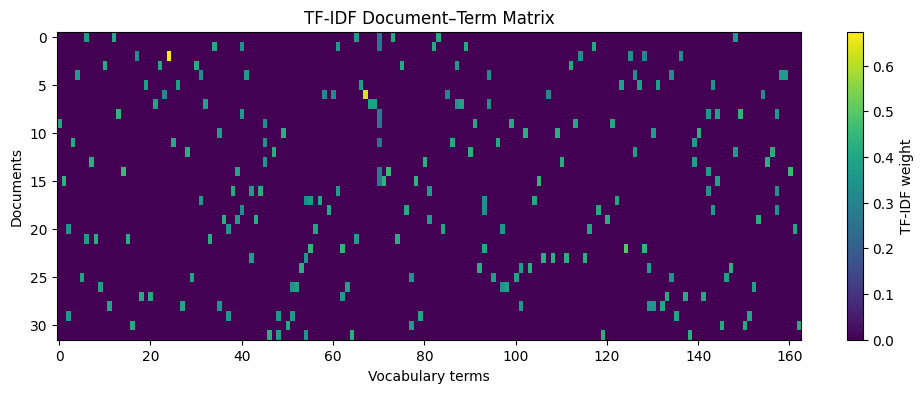

In [ ]:
plt.figure(figsize=(12, 4))
plt.imshow(X, aspect="auto", cmap="viridis", interpolation="nearest")
plt.colorbar(label="TF-IDF weight")
plt.xlabel("Vocabulary terms")
plt.ylabel("Documents")
plt.title("TF-IDF Document–Term Matrix")
plt.show()

## 5. Split the data into training and testing sets

We train the autoencoder using the training vectors and evaluate reconstruction on unseen test vectors. Since this is a small dataset, the test set is mainly for demonstrating the workflow.


In [ ]:
X_train, X_test = train_test_split(
    X, test_size=0.25, random_state=42
)

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)

Training matrix: (24, 163)
Testing matrix: (8, 163)


## 6. Build the text autoencoder

We will use a dense neural network:

- Input layer: one value for each TF-IDF vocabulary term.
- Encoder layer: reduces the dimensionality.
- Latent layer: creates the compact representation.
- Decoder layer: expands the representation back to the vocabulary dimension.
- Output layer: reconstructs the TF-IDF vector.

The output uses a sigmoid activation so that reconstructed values lie between zero and one, consistent with the range of L2-normalised TF-IDF values.


In [ ]:
input_dim = X_train.shape[1]
latent_dim = 8

inputs = keras.Input(shape=(input_dim,), name="tfidf_input")

encoded = layers.Dense(64, activation="relu", name="encoder_hidden")(inputs)
latent = layers.Dense(latent_dim, activation="relu", name="latent_representation")(encoded)

decoded = layers.Dense(64, activation="relu", name="decoder_hidden")(latent)
outputs = layers.Dense(input_dim, activation="sigmoid", name="reconstructed_tfidf")(decoded)

autoencoder = keras.Model(inputs, outputs, name="text_autoencoder")
encoder = keras.Model(inputs, latent, name="text_encoder")

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

autoencoder.summary()

Model: "text_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tfidf_input (InputLayer)        │ (None, 163)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 64)             │        10,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden (Dense)          │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_tfidf (Dense)     │ (None, 163)            │        10,595 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,187 (86.67 KB)

 Trainable params: 22,187 (86.67 KB)

 Non-trainable params: 0 (0.00 B)

### Understand the architecture

The encoder transforms each TF-IDF vector into an 8-dimensional latent vector. The decoder then attempts to reconstruct the original TF-IDF vector.

The latent dimension is a design choice. A smaller latent dimension gives stronger compression, but may lose more information. A larger latent dimension can preserve more information, but provides less compression.


### Mathematical view: How does the autoencoder learn?

Let one TF-IDF document vector be \(x\), containing \(V\) features. The encoder applies a learned weight matrix and bias, followed by an activation function, to produce a latent vector \(z\):

$$
z = f(W_e x + b_e)
$$

The decoder takes this latent vector and attempts to reconstruct the original input:

$$
\hat{x} = g(W_d z + b_d)
$$

Here, $$(W_e)$$ and $$(W_d)$$ are learned weight matrices, $$(b_e)$$ and $$(b_d)$$ are bias vectors, and $$(f)$$ and $$(g)$$ represent activation functions. In this notebook, the hidden layers use ReLU activation and the output layer uses sigmoid activation.

For a batch of documents, the model compares each original TF-IDF value with its reconstructed value. The notebook uses **mean squared error (MSE)** as its reconstruction loss:

$$
\operatorname{MSE}=\frac{1}{B\times V}\sum_{i=1}^{B}\sum_{j=1}^{V}(x_{ij}-\hat{x}_{ij})^2
$$

Here, \(B\) is the number of documents in the batch and (V) is the number of vocabulary features. Training adjusts the network weights to minimise this error. The target supplied during training is the input itself: `autoencoder.fit(X_train, X_train, ...)`.

**Important distinction:** The encoder does not select a few original words and store them directly. It learns numerical combinations of input features. A latent coordinate is therefore not automatically interpretable as a particular word or topic.

### Worked example: Calculate reconstruction loss manually

Suppose a simplified document has only four TF-IDF features. The original vector and the decoder's reconstructed vector are:

$$
x=[0.2,\ 0.8,\ 0.0,\ 0.4]
$$
$$
\hat{x}=[0.1,\ 0.6,\ 0.2,\ 0.5]
$$

The squared errors are:

$$
(0.2-0.1)^2=0.01,\quad (0.8-0.6)^2=0.04
$$
$$
(0.0-0.2)^2=0.04,\quad (0.4-0.5)^2=0.01
$$

Therefore:

$$
\operatorname{MSE}=\frac{0.01+0.04+0.04+0.01}{4}=0.025
$$

The model tries to reduce this average squared difference over all documents and features. This is a small illustrative calculation; the actual notebook computes MSE over the full TF-IDF test matrix.

In [ ]:
# Verify the hand-calculated reconstruction MSE
original_example = np.array([0.2, 0.8, 0.0, 0.4])
reconstructed_example = np.array([0.1, 0.6, 0.2, 0.5])

squared_errors = (original_example - reconstructed_example) ** 2
example_mse = np.mean(squared_errors)

print("Original vector:      ", original_example)
print("Reconstructed vector:", reconstructed_example)
print("Squared errors:       ", squared_errors)
print("Mean squared error:   ", round(example_mse, 3))

Original vector:       [0.2 0.8 0.  0.4]
Reconstructed vector: [0.1 0.6 0.2 0.5]
Squared errors:        [0.01 0.04 0.04 0.01]
Mean squared error:    0.025


## 7. Train the autoencoder

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train, X_train,
    epochs=150,
    batch_size=4,
    shuffle=True,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

print("Training completed.")

Training completed.


### Plot the training and validation loss

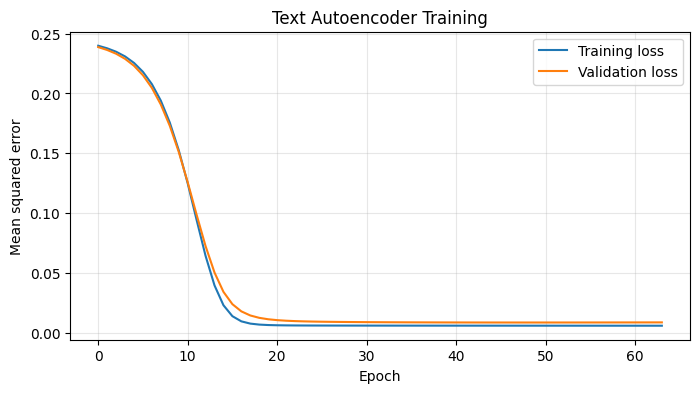

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Text Autoencoder Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** The loss measures the difference between the original TF-IDF vectors and their reconstructed versions. A decreasing loss indicates that the network is learning to reproduce the input representation. A very small training loss alone does not guarantee that the latent representation is useful for every downstream task.


## 8. Reconstruct the TF-IDF vectors

In [ ]:
X_test_reconstructed = autoencoder.predict(X_test, verbose=0)

test_mse = mean_squared_error(
    X_test.flatten(),
    X_test_reconstructed.flatten()
)

print("Test reconstruction MSE:", round(test_mse, 6))
print("Original test shape:", X_test.shape)
print("Reconstructed test shape:", X_test_reconstructed.shape)

Test reconstruction MSE: 0.007662
Original test shape: (8, 163)
Reconstructed test shape: (8, 163)


### Compare original and reconstructed feature values

The decoder produces a reconstructed numerical vector. It does not generate a sentence. We can compare the strongest TF-IDF terms in the original vector with the strongest terms in the reconstructed vector.


In [ ]:
test_indices = X_test.shape[0]
sample_position = 0

original_vector = X_test[sample_position]
reconstructed_vector = X_test_reconstructed[sample_position]

top_original = np.argsort(original_vector)[-8:][::-1]
top_reconstructed = np.argsort(reconstructed_vector)[-8:][::-1]

comparison = pd.DataFrame({
    "Original top terms": terms[top_original],
    "Original TF-IDF": original_vector[top_original],
    "Reconstructed top terms": terms[top_reconstructed],
    "Reconstructed TF-IDF": reconstructed_vector[top_reconstructed]
})

display(comparison.round(3))

,Original top terms,Original TF-IDF,Reconstructed top terms,Reconstructed TF-IDF
0,tracking,0.402,important,0.076
1,steps,0.402,student,0.070
2,measure,0.402,networks,0.067
3,fitness,0.359,educational,0.064
4,exercise,0.359,services,0.063
5,devices,0.359,technology,0.062
6,activity,0.359,follow,0.058
7,virtual,0.000,attacks,0.056


### Plot original and reconstructed values for the strongest original terms

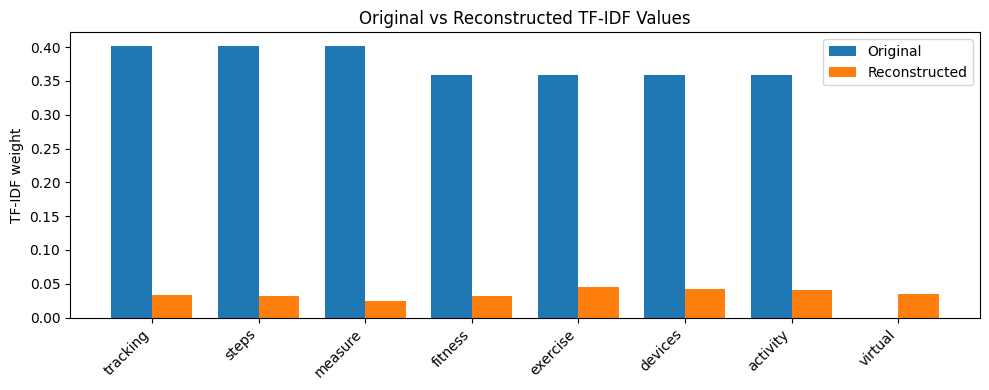

In [ ]:
selected_terms = terms[top_original]
original_values = original_vector[top_original]
reconstructed_values = reconstructed_vector[top_original]

x_pos = np.arange(len(selected_terms))
width = 0.38

plt.figure(figsize=(10, 4))
plt.bar(x_pos - width/2, original_values, width, label="Original")
plt.bar(x_pos + width/2, reconstructed_values, width, label="Reconstructed")
plt.xticks(x_pos, selected_terms, rotation=45, ha="right")
plt.ylabel("TF-IDF weight")
plt.title("Original vs Reconstructed TF-IDF Values")
plt.legend()
plt.tight_layout()
plt.show()

**Think about it:** Are the highest-weight terms preserved? Are some terms assigned a non-zero reconstructed value even if they were zero in the original vector? What might this tell us about information loss during compression?


## 9. Extract the latent representations

In [ ]:
Z = encoder.predict(X, verbose=0)

print("Original TF-IDF shape:", X.shape)
print("Latent representation shape:", Z.shape)

latent_df = pd.DataFrame(
    Z,
    columns=[f"Latent_{i+1}" for i in range(Z.shape[1])]
)
latent_df["category"] = labels
display(latent_df.head())

Original TF-IDF shape: (32, 163)
Latent representation shape: (32, 8)


,Latent_1,Latent_2,Latent_3,Latent_4,Latent_5,Latent_6,Latent_7,Latent_8,category
0,1.268007,1.859209,1.280522,0.929866,0.550909,0.0,0.020954,1.580562,Technology
1,1.135647,1.935465,0.850320,0.908078,0.596594,0.0,0.116931,1.396671,Technology
2,1.559606,1.291029,0.957353,0.532947,0.560656,0.0,0.053318,1.465140,Technology
3,1.087164,1.400287,1.069643,0.614835,0.465079,0.0,0.189013,1.477887,Technology
4,1.036159,1.804409,1.113722,0.894268,0.678982,0.0,0.000000,1.086042,Technology


The original TF-IDF matrix has one feature for each vocabulary term. The latent matrix has only eight features per document. These latent values are learned by the encoder during training.

The values do not correspond directly to individual words. Instead, each latent dimension is a learned combination of input features.


### Interpreting the learned latent representation

The latent vector is a compressed numerical description of the original TF-IDF document vector. It is learned because the encoder's weights are adjusted during training to help the decoder reconstruct the input.

Consider what compression means in this practical:

- The input has one coordinate for each term in the vocabulary.
- The latent representation has only a small number of coordinates (eight in the initial model).
- Each latent coordinate can combine information from many TF-IDF input features.
- The decoder uses the compressed values to estimate the original TF-IDF weights.

**What information may be lost?** When many input features are compressed into fewer latent dimensions, the model may not preserve every small TF-IDF value. Some terms may receive lower reconstructed weights, and terms that were originally zero may receive small non-zero reconstructed values. This is an expected possibility in approximate reconstruction.

**Does a low reconstruction error mean that the model understands the meaning of the text?** No. The training objective rewards accurate reconstruction of TF-IDF values. It does not directly reward synonym understanding, sentence meaning, word order, factual reasoning or classification accuracy. Two semantically similar documents may be close in latent space, but this is not guaranteed by the reconstruction objective alone.

**How should you interpret a latent coordinate?** Treat it as a learned feature, not as a named topic or a word, unless a separate analysis provides evidence for that interpretation. The category labels used later are only for visual inspection; they are not used to train the autoencoder.

### Result-analysis activity

After running the model, use the outputs from the reconstruction and latent-space sections to answer:

1. Identify one term whose reconstructed TF-IDF value is close to its original value.
2. Identify one term whose value changes noticeably after reconstruction.
3. Does the model assign non-zero reconstructed values to terms that were absent from the original document?
4. Compare two documents from the same category. Are their latent coordinates close in the plotted projection?
5. Compare documents from different categories. Are any of them close together? Suggest why this might happen.

Support your observations with values from the notebook. Do not conclude that the model has learned semantic categories from the plot alone.

## 10. Visualise the latent space in two dimensions

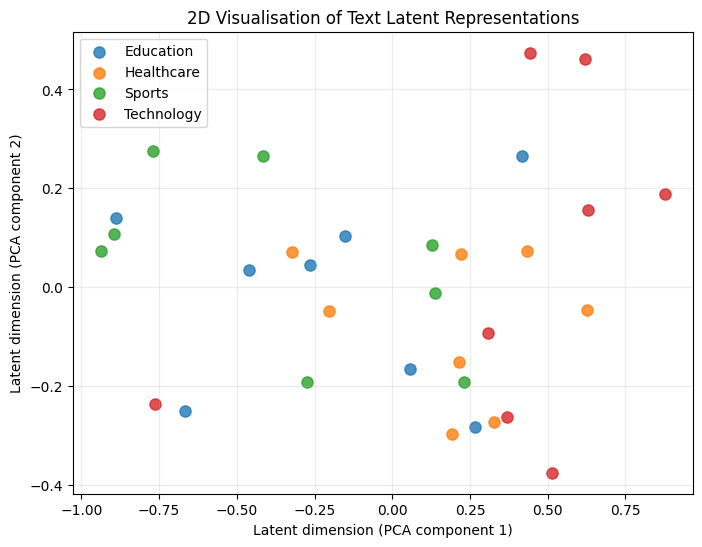

In [ ]:
# If the latent dimension is greater than 2, use PCA only for visualisation.
Z_2d = PCA(n_components=2, random_state=42).fit_transform(Z)

plt.figure(figsize=(8, 6))
for category in sorted(data["category"].unique()):
    mask = data["category"].values == category
    plt.scatter(
        Z_2d[mask, 0],
        Z_2d[mask, 1],
        label=category,
        s=65,
        alpha=0.8
    )

plt.xlabel("Latent dimension (PCA component 1)")
plt.ylabel("Latent dimension (PCA component 2)")
plt.title("2D Visualisation of Text Latent Representations")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**How to interpret this plot**

Each point represents one document. Points that are close together have similar coordinates in the projected latent space. The colours indicate the original categories, but the autoencoder was not trained with these labels.

Do not expect perfect category separation. The dataset is small, and the autoencoder was trained only to reconstruct TF-IDF vectors—not to classify documents. PCA is used here to project the learned latent vectors into two dimensions; it is not the autoencoder's latent layer.


## 11. Experiment: What happens when the latent dimension changes?

We will train separate autoencoders using different bottleneck sizes. Compare reconstruction error to understand the effect of compression.

A smaller bottleneck imposes stronger compression. A larger bottleneck gives the network more capacity to retain input information. Reconstruction error is only one measure; it does not by itself measure semantic quality.


In [ ]:
def build_and_evaluate_autoencoder(X_train, X_test, latent_dim, epochs=120):
    input_dim = X_train.shape[1]

    inp = keras.Input(shape=(input_dim,))
    x = layers.Dense(64, activation="relu")(inp)
    z = layers.Dense(latent_dim, activation="relu", name="latent")(x)
    x = layers.Dense(64, activation="relu")(z)
    out = layers.Dense(input_dim, activation="sigmoid")(x)

    model = keras.Model(inp, out)
    model.compile(optimizer="adam", loss="mse")

    stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )

    model.fit(
        X_train, X_train,
        epochs=epochs,
        batch_size=4,
        validation_split=0.2,
        callbacks=[stop],
        verbose=0
    )

    prediction = model.predict(X_test, verbose=0)
    mse = mean_squared_error(X_test.flatten(), prediction.flatten())
    return model, mse

latent_dimensions = [2, 4, 8, 16, 24]
results = []

for dim in latent_dimensions:
    model, mse = build_and_evaluate_autoencoder(
        X_train, X_test, latent_dim=dim
    )
    results.append({"Latent dimension": dim, "Test reconstruction MSE": mse})

results_df = pd.DataFrame(results)
display(results_df.round(6))

,Latent dimension,Test reconstruction MSE
0,2,0.009240
1,4,0.008359
2,8,0.008159
3,16,0.007533
4,24,0.007288


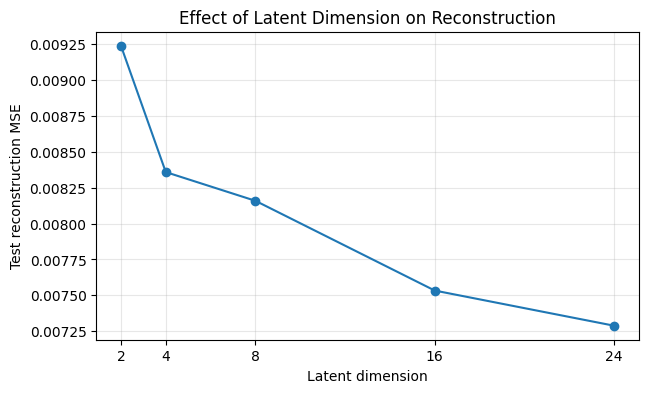

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(
    results_df["Latent dimension"],
    results_df["Test reconstruction MSE"],
    marker="o"
)
plt.xlabel("Latent dimension")
plt.ylabel("Test reconstruction MSE")
plt.title("Effect of Latent Dimension on Reconstruction")
plt.xticks(latent_dimensions)
plt.grid(alpha=0.3)
plt.show()

**Observe and explain:**

- Which latent dimension gives the lowest reconstruction error?
- What happens when the latent dimension is reduced to two?
- Does increasing the latent dimension always guarantee a useful representation?
- What trade-off exists between compression and reconstruction?


## 12.Compare with PCA

PCA is a linear dimensionality-reduction method. An autoencoder can learn nonlinear transformations, depending on its architecture and activation functions. Compare the reconstruction errors of PCA and the autoencoder using the same number of components.

This comparison is illustrative: the models have different assumptions and training procedures.


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=8, random_state=42)
pca.fit(X_train)

X_test_pca_reconstructed = pca.inverse_transform(
    pca.transform(X_test)
)

pca_mse = mean_squared_error(
    X_test.flatten(),
    X_test_pca_reconstructed.flatten()
)

ae_mse = mean_squared_error(
    X_test.flatten(),
    autoencoder.predict(X_test, verbose=0).flatten()
)

print("PCA reconstruction MSE:", round(pca_mse, 6))
print("Autoencoder reconstruction MSE:", round(ae_mse, 6))

PCA reconstruction MSE: 0.006034
Autoencoder reconstruction MSE: 0.007662


## 13. Mandatory to complete: Exercises


### Exercise 1: Change the vocabulary size
Change `max_features` in the `TfidfVectorizer`. Observe how the number of input features and the reconstruction error change.

### Exercise 2: Change the latent dimension
Train the autoencoder with latent dimensions of 2, 4, 8 and 16. Compare reconstruction errors and discuss the compression–reconstruction trade-off.

### Exercise 3: Add more text samples
Add at least five new documents to each category. Retrain the vectorizer and autoencoder. Observe whether the latent-space visualisation changes.

### Exercise 4: Try a new category
Add a fifth category, such as environment or finance. Include several documents and examine the latent-space plot.

### Exercise 5: Interpret reconstruction
For three test documents, compare the top original TF-IDF terms with the top reconstructed terms. Record which terms are preserved and which are lost.

### Exercise 6: Compare PCA and the autoencoder
Compare their reconstruction errors using the same number of latent dimensions. Explain why the results may differ.


## 14. Reflection questions

1. Why must text be converted into numerical vectors before it is passed to a dense neural network?
2. What does each dimension of the TF-IDF vector represent?
3. What is the role of the encoder?
4. Why is the bottleneck layer called a latent representation?
5. Does the latent vector store the original words directly?
6. Why does a smaller latent dimension generally increase the compression challenge?
7. How is a text autoencoder different from an RNN?
8. Why does this TF-IDF autoencoder not reconstruct the original sentence word by word?
9. Why might two documents with similar topics have nearby latent representations?
10. What are the limitations of using a small dataset for this experiment?


## 15. Key takeaways

- Text must be represented numerically before it can be processed by a neural network.
- TF-IDF creates a document–term representation based on term importance.
- An autoencoder learns to compress and reconstruct this numerical representation.
- The encoder's output is a compact latent representation.
- The latent dimension controls the degree of compression.
- A two-dimensional plot can help inspect the latent space, but it is only a projection.
- This practical reconstructs TF-IDF vectors; it does not generate natural-language sentences.
- Unlike an RNN, this TF-IDF-based dense autoencoder does not model word order or sequential dependencies.

### Connection to the next topic

Autoencoders demonstrate how neural networks can learn compact representations without class labels. These learned representations are useful in dimensionality reduction, visualisation, anomaly detection and other machine-learning tasks.


## References and further reading
1. Scikit-learn documentation: `TfidfVectorizer`.
2. TensorFlow/Keras documentation: Functional API and model training.


